---
title: ""
lang: uk
format:
  typst:
    mainfont: "Times New Roman"
    fontsize: 14pt
    margin: { x: 2.5cm, y: 2.5cm }
  docx: default
  pdf:
    pdf-engine: lualatex
    mainfont: "Times New Roman"
---

::: {.content-visible when-format="typst"}

```{=typst}
// Configure the page.
#set page(
  paper: "a4",
  // The margins depend on the paper size.
  margin: (x: 2cm, y: 1.5cm),
  numbering:  (current, total) => if current > 1 { current }, number-align: right, 
)

// Configure styling
#set par(
  leading: 0.8em,
  spacing: 1em,
  justify: true,
)
#show table: set text(size: 9pt)

#align(top + center)[
  Міністерство освіти і науки України \
  Національний університет «Львівська політехніка» \
  Кафедра систем штучного інтелекту \
  \
  #image("logo.png", width: 6cm)
  \
  #set par(spacing: 0.4em)
  #text(size: 24pt, weight: "bold")[Звіт]
  #set par(spacing: 0.8em)

  *про виконання лабораторної роботи № 2* \
  _з дисципліни:_ «Обробка мови методами штучного інтелекту»
]

#align(bottom + right)[
  Виконав: \
  студент групи ШІ-42 \
  Горишевський Олексій Олександрович
]

#pagebreak()
```

:::

# Workbook 02: Exploring word embeddings

В цій лабораторній ми детальніше розберемося з векторним представленням слів (word embeddings), а саме:

- Завантажимо вектори GloVe
- Перевіримо цікаві властивості цих векторів

У вас буде кілька завдань. Відповіді на завдання відправляють функції `lab.checkpoint()` та `lab.answer()`.

Для початку, заповніть параметр `email` нижче:

In [26]:
%pip install --quiet --ignore-installed requests==2.32.4 https://static.lp-nlp.com/pypi/lpnlp-2025.12.14-py3-none-any.whl

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import lpnlp

lab = lpnlp.start(
    email="oleksii.ivanov.shi.2023@lpnu.ua", lab="exploring_word_embeddings"
)

Удачі!


# GloVe

In [28]:
%pip install --quiet gensim tqdm

Note: you may need to restart the kernel to use updated packages.


Повний GloVe містить 4,000,000 векторів і займає багато пам'яті. Щоб уникнути проблем з пам'ятю, залишимо лише 50,000 векторів найчастотніших слів. Це трохи знизить якість моделей, але це зараз не головне.

In [29]:
import gensim.downloader
from gensim.models import KeyedVectors
import tqdm


# Ця функція завантажить повний набір GloVe векторів та залишить `max_n` з них
def load_glove_subset(max_n: int) -> KeyedVectors:
    """Return top `max_n` word vectors. """
    all_glove = gensim.downloader.load("glove-wiki-gigaword-200")
    subset = KeyedVectors(all_glove.vector_size)
    for word in tqdm.tqdm(all_glove.key_to_index, total=max_n):
        if len(subset.vectors) >= max_n:
            break
        subset.add_vector(word, all_glove[word])
    return subset

# Цей виклик може зайняти хвилин 5-6, тож ми завантажимо вже готові 50k векторів
# glove = load_glove_subset(50_000)
glove = KeyedVectors.load("http://static.lp-nlp.com/files/glove-50k.bin")

In [30]:
lab.checkpoint("glove subset size", len(glove.key_to_index))

Відповідь правильна ✅



50000

Об'єкт `glove` може працювати як звичайний словник (`dict`), ключами якого є токени, а значеннями - вектори слів. Вектори, які ми завантажили, були натреновані на lower-cased текстах, тож і шукати вектори треба для слів у нижньому регістрі.

Подивимося, як виглядає вектор слова "ukraine":

In [31]:
glove["ukraine"]

array([-2.9835e-01,  2.0119e-01,  1.0576e+00, -3.0105e-01, -4.6139e-01,
       -2.3603e-02,  7.0583e-01,  2.5945e-01,  2.8852e-01,  5.5536e-01,
       -4.9120e-01,  2.6961e-01, -2.4428e-02, -2.1458e-02,  1.1455e+00,
        6.8221e-01, -2.9128e-01, -2.2623e-01, -2.0675e-01,  1.3855e-01,
       -1.8925e-01,  2.3665e+00, -9.9162e-01, -2.4470e-01,  2.4622e-01,
       -1.1827e-01,  3.8615e-01, -2.6921e-01, -3.8376e-02, -5.2927e-01,
       -8.2827e-02, -2.8802e-01, -4.3625e-01, -2.1721e-01, -9.3741e-01,
        4.2792e-01, -8.3241e-01, -3.7487e-02, -5.8459e-01, -5.4755e-01,
       -5.6027e-01,  1.8893e-01,  1.4222e-01,  2.0484e-01,  2.0384e-01,
       -3.7074e-01,  4.3972e-01, -3.4872e-01,  1.2722e-01, -4.1341e-01,
        7.1163e-01, -6.5506e-01, -4.4388e-01,  1.9223e-01, -3.9496e-01,
       -6.6644e-01, -5.9630e-01, -7.9109e-02,  5.3330e-01,  9.3981e-01,
       -7.1796e-01,  5.0569e-01,  6.4526e-01, -2.6927e-01,  3.8530e-01,
        5.5825e-01,  6.5299e-02,  3.5928e-01,  2.3044e-01, -2.33

### Завдання

Знайдіть кількість та середнє значення (mean) елементів вектора слова "ukraine"

In [61]:
size_v_ukraine = glove["ukraine"].shape[0]
mean_v_ukraine = float(glove["ukraine"].mean())

lab.checkpoint("size of 'ukraine'", size_v_ukraine)
lab.checkpoint("mean of 'ukraine'", mean_v_ukraine)

Відповідь правильна ✅

Відповідь правильна ✅



0.03348933160305023

# Подібність слів

### Косинус подібності (cosine similarity)

Дуже часто метрикою близькості двох векторів слугує косинус подібності (cosine similarity). Косинус кута між двома векторами буде дорівнювати 1, коли напрями векторів точно збігаються. Для ортогональних векторів косинус дорівнює 0, а для протилежних -1.

Косинус кута можна порахувати через векторний добуток:

$$ \text{similarity}(p, q) = \cos {\theta} = \frac {p \cdot q} {|p| |q|} $$

$|x|$ означає довжину вектора $x$:

$$|x| = \sqrt {x ^ 2} $$

### Завдання

Напишіть функцію обчислення cosine similarity

In [57]:
import numpy as np

def normalize(v):
    return v / np.sqrt(v @ v)

def cosine_similarity(v1: np.ndarray, v2: np.ndarray) -> float:
    similarity = normalize(v1) @ normalize(v2)
    return float(similarity)

# Знайдіть косинус подібності слів "apple" та "google"
cos_0 = cosine_similarity(glove["apple"], glove["google"])
assert isinstance(cos_0, float)
lab.checkpoint("cosine similarity between 'apple' and 'google'", float(cos_0))

Відповідь правильна ✅
Так, вірно! 💪


0.5554561018943787

### Завдання

Знайти подібність словa "awesome" до слів "amazing", great" та "bad"

In [58]:
cos_1 = cosine_similarity(glove['awesome'], glove['amazing'])
lab.checkpoint("cosine_similarity between 'awesome' and 'amazing'", cos_1)

Відповідь правильна ✅
Так, вірно! 💪


0.6967080235481262

In [59]:
cos_2 = cosine_similarity(glove['awesome'], glove['great'])
lab.checkpoint("cosine_similarity between 'awesome' and 'great'", cos_2)

Відповідь правильна ✅
Так, вірно! 💪


0.45695698261260986

In [60]:
cos_3 = cosine_similarity(glove['awesome'], glove['bad'])
lab.checkpoint("cosine_similarity between 'awesome' and 'bad'", cos_3)

Відповідь правильна ✅
Так, вірно! 💪


0.3114391565322876

## Пошук подібних слів

Завдяки векторному представленню, ми можемо уявляти собі слова точками в багатовимірному просторі. Близькі за семантикою (змістом) або морфологією (як одиниці мови) слова будуть відповідати близькими між собою точками.

Атож, найближчі сусіди слова будуть або синонимами, або антонімами, або виконувати ту саму роль в реченні.

Як знайти сусідів вектора певного слова? Наївне рішення — перебрати всі вектори і обчислити відстань до кожного з них. Для великих словників це може зайняти багато часу. Для великих словників або коли необхідно робити багато запитів, використовують методи приблизного пошуку векторів, такі як LSH або [faiss](https://github.com/facebookresearch/faiss). Ці методи попередньо будують індекси для векторів, які дозволяють здійснювати пошук подібних векторів дуже швидко (і з маленькою, але ненульовою ймовірністю пропускати деяких сусідів)

Оскільки наш словник є дуже невеликим (50 тисяч токенів), то можемо дозволити собі наївне рішення.

In [62]:
from typing import List, Tuple

def find_similar(word: str , top_n: int = 10) -> List[Tuple[float, str]]:
    """Повертає `top_n` сусідів слова `word` разом з подібністю.

    Returns:
        list of (similarity, word) tuples.
    """
    # Рахуємо подібність вектора слова `word` з кожним іншим словом
    # Словник всіх слів міститься в `glove.vocab`

    result = []
    for other_word in glove.key_to_index:
        if other_word == word:
            continue
        similarity = cosine_similarity(glove[word], glove[other_word])
        result.append((similarity, other_word))
    result.sort(reverse=True, key=lambda x: x[0])
    result = result[:top_n]

    return result


find_similar("awesome")

[(0.7240041494369507, 'unbelievable'),
 (0.7075759172439575, 'incredible'),
 (0.6967080235481262, 'amazing'),
 (0.6145412921905518, 'fantastic'),
 (0.6071451306343079, 'terrific'),
 (0.5814316868782043, 'marvelous'),
 (0.5781935453414917, 'awful'),
 (0.5776978135108948, 'wonderful'),
 (0.5741086602210999, 'phenomenal'),
 (0.5519749522209167, 'tremendous')]

In [63]:
similar_to_based = find_similar("based", top_n=5)
similar_to_based

[(0.6398434638977051, 'which'),
 (0.6247483491897583, 'company'),
 (0.616948127746582, 'according'),
 (0.594972550868988, 'example'),
 (0.588263750076294, 'group')]

In [64]:
find_similar("awful")

[(0.8684825897216797, 'horrible'),
 (0.8322069644927979, 'terrible'),
 (0.7476429343223572, 'dreadful'),
 (0.6913045644760132, 'unbelievable'),
 (0.6799401044845581, 'horrendous'),
 (0.6458765864372253, 'appalling'),
 (0.6423128843307495, 'really'),
 (0.6418579816818237, 'bad'),
 (0.6389516592025757, 'horrifying'),
 (0.6362232565879822, 'thing')]

In [65]:
similar_to_green = find_similar("green")
similar_to_green

[(0.6953294277191162, 'red'),
 (0.6699603796005249, 'yellow'),
 (0.6597475409507751, 'blue'),
 (0.6384711861610413, 'brown'),
 (0.6299036145210266, 'orange'),
 (0.6277689933776855, 'purple'),
 (0.6158420443534851, 'bright'),
 (0.6116896867752075, 'black'),
 (0.585483968257904, 'pink'),
 (0.5821937918663025, 'white')]

In [66]:
lab.checkpoint("most similar to 'green'", find_similar("green")[0][1])

Відповідь правильна ✅
Цей крок не має автоматичної перевірки, рухаємося далі


'red'

## Швидший пошук сусідів (векторизований)

Наша функція `find_similar` є навмисно «наївною»: вона перебирає весь словник і обчислює косинусну подібність по одному слову за раз.

Ми можемо суттєво прискорити це, виконавши те саме обчислення за один крок:

- Нормалізуємо всі вектори слів один раз (тоді косинусна подібність зводиться до скалярного добутку).
- Для запитуваного слова беремо його нормалізований вектор і обчислюємо скалярний добуток з усією матрицею нормалізованих векторів.
- Вибираємо топ-N результатів за найвищими оцінками.

Це дозволяє уникнути циклів Python та використовує оптимізовану лінійну алгебру «під капотом».

In [42]:
import numpy as np
from typing import List, Tuple

# Build a matrix of all vectors (shape: vocab_size x dim) and normalize it once.
all_words = glove.index_to_key
W = glove.vectors.astype(np.float32)

# Normalize each row to unit length
W_norm = W / np.linalg.norm(W, axis=1, keepdims=True)

def find_similar_fast(word: str, top_n: int = 10) -> List[Tuple[float, str]]:
    """Return the `top_n` nearest neighbors of `word` (fast vectorized version)."""

    if word not in glove.key_to_index:
        raise KeyError(f"Word '{word}' not in vocabulary")

    idx = glove.key_to_index[word]
    v = W_norm[idx]  # already normalized

    # Cosine similarity with all words (since both are normalized)
    sims = W_norm @ v

    # Exclude the query word itself
    sims[idx] = -np.inf

    # Get indices of the top_n highest similarities
    top_idx = np.argsort(-sims)[:top_n]

    return [(float(sims[i]), all_words[i]) for i in top_idx]

find_similar_fast("awesome")


[(0.7240041494369507, 'unbelievable'),
 (0.7075759172439575, 'incredible'),
 (0.6967080235481262, 'amazing'),
 (0.6145411729812622, 'fantastic'),
 (0.6071450710296631, 'terrific'),
 (0.5814316868782043, 'marvelous'),
 (0.5781934261322021, 'awful'),
 (0.5776978135108948, 'wonderful'),
 (0.5741087198257446, 'phenomenal'),
 (0.5519749522209167, 'tremendous')]

Бібліотека `gensim`, за допомогою якої ми завантажували вектори, також вміє робити пошук подібних векторів, але значно швидше. Порівняємо з нашою імплементацією:

In [43]:
%%time
glove.most_similar("facebook")

CPU times: user 180 ms, sys: 3.74 ms, total: 183 ms
Wall time: 21 ms


[('twitter', 0.8435288667678833),
 ('myspace', 0.8185951113700867),
 ('youtube', 0.7537195086479187),
 ('google', 0.671447217464447),
 ('blogs', 0.6526655554771423),
 ('blog', 0.6467068195343018),
 ('web', 0.6389559507369995),
 ('website', 0.6388846039772034),
 ('zuckerberg', 0.6286188960075378),
 ('websites', 0.6250429749488831)]

In [67]:
%%time
find_similar("facebook")

CPU times: user 292 ms, sys: 1.98 ms, total: 294 ms
Wall time: 300 ms


[(0.8435288071632385, 'twitter'),
 (0.8185950517654419, 'myspace'),
 (0.7537195086479187, 'youtube'),
 (0.6714472770690918, 'google'),
 (0.6526655554771423, 'blogs'),
 (0.646706759929657, 'blog'),
 (0.6389558911323547, 'web'),
 (0.6388846039772034, 'website'),
 (0.6286188364028931, 'zuckerberg'),
 (0.6250429749488831, 'websites')]

### Завдання

Знайдіть найближчого сусіда до слова `cat` (одне слово)

In [45]:
cat_top_synonym = find_similar_fast("cat", top_n=1)[0][1]
cat_top_synonym_std = glove.most_similar("cat", topn=1)[0][0]
assert isinstance(cat_top_synonym, str)
assert cat_top_synonym == cat_top_synonym_std
lab.checkpoint("Most similar word to `cat`", cat_top_synonym)

Відповідь правильна ✅
Цей крок не має автоматичної перевірки, рухаємося далі


'dog'

### Завдання

Спробуйте функцію `find_similar` на різних словах. Які пари здалися вам найбільш цікавими, дивними або нелогічними?

In [46]:
interesting_pair = [
    ("green", similar_to_green[0][1]),
    ("cat", cat_top_synonym),
    ("based", similar_to_based[0][1])
]
lab.checkpoint("Interesting/strange pairs", interesting_pair)

Відповідь правильна ✅
Цей крок не має автоматичної перевірки, рухаємося далі


[('green', 'red'), ('cat', 'dog'), ('based', 'which')]

# Візуалізація

In [70]:
from sklearn import manifold
import matplotlib.pyplot as plt


def plot_word_embeddings(model, search_list):
    words = []
    for term in search_list:
        words += [w[0] for w in model.most_similar([term], topn=5)]
    words += search_list
    words = list(set(words))

    vectors = model[words]

    tsne = manifold.TSNE(n_components=2, random_state=0, max_iter=10000, perplexity=7)
    T = tsne.fit_transform(vectors)

    plt.figure(figsize=(16, 10))
    plt.scatter(T[:, 0], T[:, 1])
    for label, x, y in zip(words, T[:, 0], T[:, 1]):
        plt.annotate(label, xy=(x+2, y+2), xytext=(0, 0), textcoords='offset points')

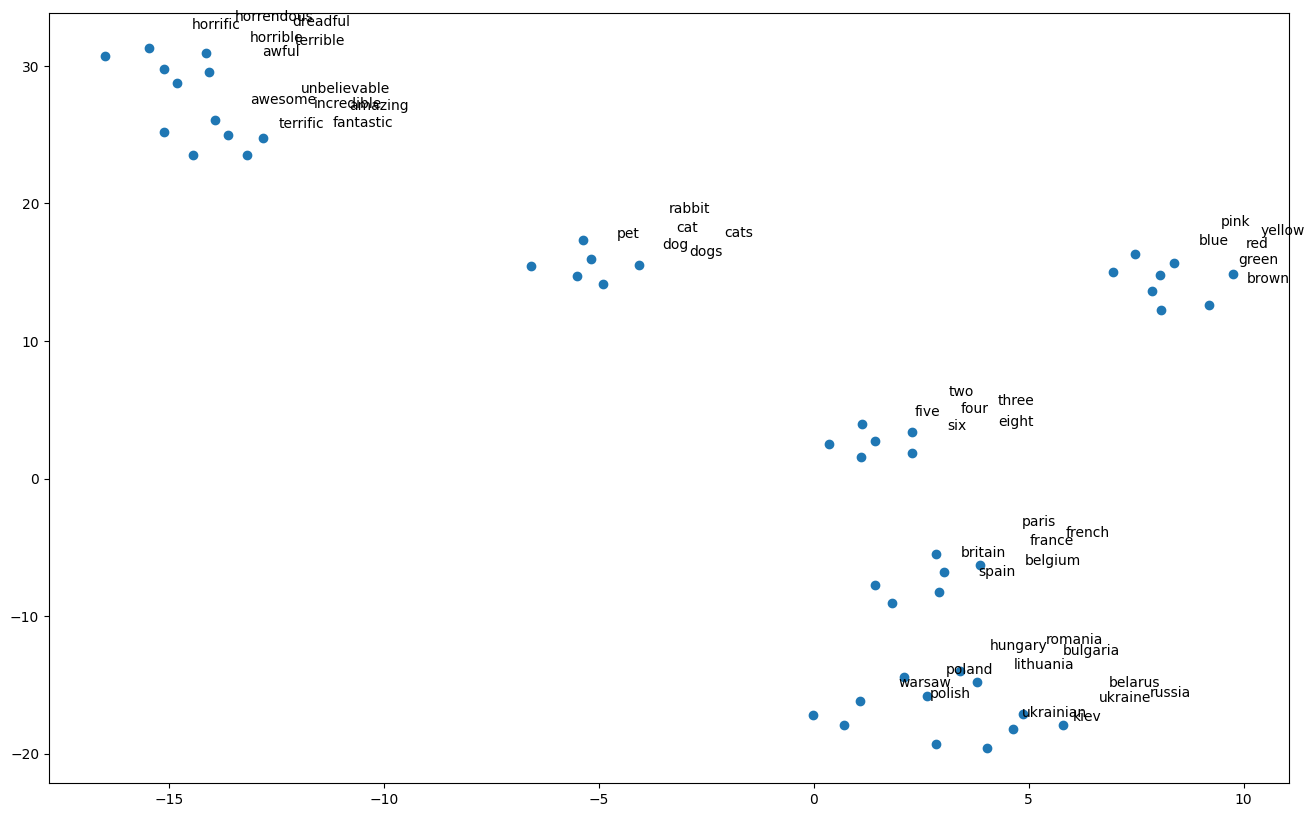

In [71]:
plot_word_embeddings(glove, ["awesome", "terrible", "ukraine", "poland", "france", "red", "green", "cat", "two"])

# Векторна арифметика

Ми можемо додавати та віднімати вектори слів. Результат таких операцій (який теж буде вектором) можна перетворити назад в слово. Для цього знайдемо кілька найближчих до результата векторів і подивимося, які слова їм відповідають.

Векторну аріфметику використовують для пошуку слів за аналогіями. Класичний приклад з першої статті про Word2Vec виглядає так:

```
V("king") - V("man") + V("woman") ~= V("queen")
```

In [49]:
glove.similar_by_vector(glove["king"] - glove["man"] + glove["woman"])

[('king', 0.8209066987037659),
 ('queen', 0.7119165658950806),
 ('princess', 0.6121214628219604),
 ('monarch', 0.6024806499481201),
 ('prince', 0.596004068851471),
 ('throne', 0.5915313363075256),
 ('daughter', 0.5588055849075317),
 ('elizabeth', 0.554740309715271),
 ('kingdom', 0.5494517087936401),
 ('mother', 0.5419816970825195)]

### Завдання

Знайдіть найближчий вектор виразу
`paris` - `france` + `ukraine`

In [72]:
answer = glove.most_similar(positive=["paris", "ukraine"], negative=["france"], topn=1)[0][0]
lab.answer(answer)   # мені теж не подобається те, як написана відповідь :)

Відповідь правильна ✅
Так, вірно! 💪


'kiev'

# Висновки

1. За допомогою векторного представлення слів можна знаходити синоніми, антоніми та слова, які виконують схожі функції в реченні.
2. Векторна арифметика дозволяє знаходити слова за аналогіями.
3. Векторне представлення слів дозволяє візуалізувати слова у двовимірному просторі, що допомагає краще зрозуміти їх семантичні зв'язки.
4. Найближчі сусіди часто були такими, які "йдуть в парі" з вихідним словом або були однієї категорії (наприклад "cat" and "dog").
5. "Kiev" і мені не подобається, але скоріш за все ця транслітерація просто більш поширена, ніж коректна "Kyiv".